# 01 Exploratory data analysis and data quality

The work runs in five steps. First structure and coverage, then data-quality checks (each one turned into a function in `ahu_fdd/clean.py`), then patterns across buildings and units, then what each fault does to the signals checked against the labels, and last the periods that look like faults but carry no label.

Figures are written to `../../report/figures/` for the report.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ahu_fdd.config import CODE_DIR, load_labels, load_metadata, FAULTS
from ahu_fdd.clean import load_all_raw, load_clean
from ahu_fdd.features import add_physics

FIG = CODE_DIR.parent / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
meta, labels = load_metadata(), load_labels()
raw = load_all_raw()

## 1. Structure and coverage

In [2]:
expected = raw.groupby(["split", "ahu_id"])["timestamp"].agg(["min", "max", "size"])
expected["expected"] = ((expected["max"] - expected["min"]) / pd.Timedelta("5min") + 1).astype(int)
print(raw.shape)
print(expected.groupby(level=0)[["size", "expected"]].sum())
print("NaN share per column (train):")
print(raw[raw.split == "train"].isna().mean().loc[lambda s: s > 0].round(4))
print(meta.groupby("building")[["has_co2_sensor", "has_airflow_station"]].mean())
print(labels.fault_type.value_counts())

(2765527, 21)
          size  expected
split                   
test    711994    714239
train  2053533   2085120
NaN share per column (train):
fan_power_kw         0.0020
sat_c                0.0020
mat_c                0.0020
rat_c                0.0020
chw_valve_cmd_pct    0.0020
co2_ppm              0.3054
sa_flow_m3h          0.7103
dtype: float64
          has_co2_sensor  has_airflow_station
building                                     
B1                   1.0                  0.0
B2                   1.0                  1.0
B3                   0.0                  0.0
fault_type
chw_valve_stuck      8
oa_damper_stuck      7
low_coil_capacity    7
sat_sensor_bias      6
Name: count, dtype: int64


The raw data holds 2,765,527 rows. Train covers 2,053,533 of 2,085,120 expected 5-minute rows (98.5%) and test 711,994 of 714,239 (99.7%), so the gaps are short. Missing values are rare (0.2% on the core signals) except where a sensor does not exist. CO2 is missing for 31% of rows because B3 has no CO2 sensor, and airflow for 71% because only B2 has an airflow station. The 28 labelled events are spread evenly across the four fault types (6 to 8 each), which is very few per class and drives the validation design in notebook 02.

## 2. Data-quality checks

Each check below was found by looking at the data, then written as a rule in `clean.py` so the same
rule runs on the test period and, later, in production. The log records every change.

In [3]:
key = ["ahu_id", "timestamp"]
dup = raw[raw.duplicated(key, keep=False)]
print("duplicate (ahu, timestamp) rows:", len(dup))
print(dup.groupby([dup.ahu_id.str[:2], dup.timestamp.dt.date]).size().rename("rows"))

duplicate (ahu, timestamp) rows: 9924
ahu_id  timestamp 
B1      2025-06-01    3046
B3      2025-02-14    6878
Name: rows, dtype: int64


There are two kinds of duplicates.
* **B3, 14 Feb.** Identical rows were exported twice (6,878 duplicated rows, so 3,439 extra copies). One copy is dropped.
* **B1, 1 Jun from 16h00.** Here the 3,046 duplicated rows hold two *different* readings per timestamp, and B1 later has an 8-hour hole. That is the signature of a logger writing UTC for a week, so rows labelled 1 Jun 16h00 to 8 Jun 16h00 belong 8 hours later. The outdoor air temperature proves it, because all three buildings share the same weather.

as logged mean |B1 - reference| = 3.61 °C
fixed mean |B1 - reference| = 0.33 °C


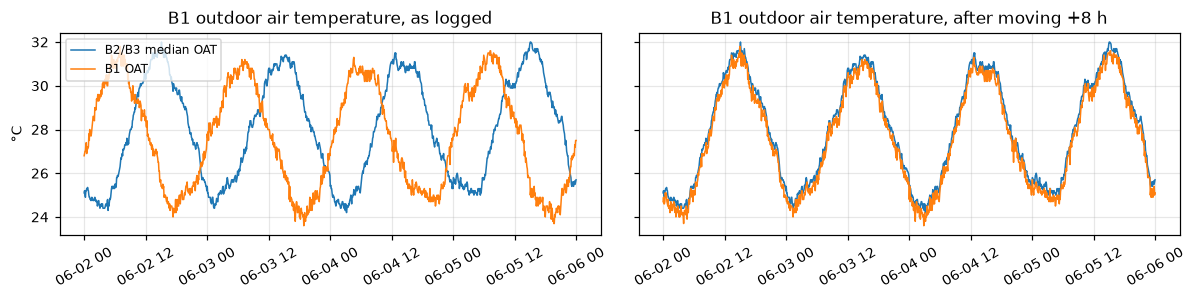

In [4]:
oat_ref = raw[raw.ahu_id.str[:2] != "B1"].groupby("timestamp").oat_c.median()
b1 = raw[raw.ahu_id == "B1-AHU-01"].set_index("timestamp").oat_c
clean = load_clean()
b1c = clean[clean.ahu_id == "B1-AHU-01"].set_index("timestamp").oat_c
win = slice("2025-06-02", "2025-06-05")
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
for a, s, title in [(ax[0], b1, "as logged"), (ax[1], b1c, "after moving +8 h")]:
    a.plot(oat_ref.loc[win], lw=1, label="B2/B3 median OAT")
    a.plot(s[~s.index.duplicated()].loc[win], lw=1, label="B1 OAT")
    a.set_title(f"B1 outdoor air temperature, {title}")
    a.tick_params(axis="x", labelrotation=30)
ax[0].set_ylabel("°C"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "clock_shift.png", dpi=170)
for name, s in [("as logged", b1), ("fixed", b1c)]:
    s = s[~s.index.duplicated()].loc["2025-06-02":"2025-06-07"]
    print(name, "mean |B1 - reference| =", round((s - oat_ref.reindex(s.index)).abs().mean(), 2), "°C")

As logged, B1's outdoor air temperature differs from the other two buildings by 3.61 °C on average over the shifted week. After moving those rows 8 hours later the gap falls to 0.33 °C, which is ordinary sensor spread. The left chart shows B1 out of step with the reference curve, the right one shows the two curves on top of each other after the fix.

In [5]:
df, log = load_clean(return_log=True)
log

,issue,building,rows,detail
0,clock shift (logger wrote UTC),B1,32153,labels 2025-06-01 16:00:00 to 2025-06-08 16:00...
1,duplicate export,B3,3439,days ['2025-02-14']; kept first copy
2,"fan power in W, not kW",B3-AHU-04,6023,2025-04-01 to 2025-04-21: divided by 1000
3,CO2 at 0 or 5000 ppm (sensor failure),B2-AHU-03,781,2025-01-20 01:00:00 to 2025-02-27 22:55:00: se...
4,sat_c frozen (flatline),B2-AHU-08,2587,2025-07-21 00:00:00 to 2025-07-29 23:55:00 at ...
5,rat_c frozen (flatline),B1-AHU-07,2239,2025-05-05 07:00:00 to 2025-05-26 19:25:00 at ...
6,logging gap,B2,0,2025-03-10 05:55:00 to 2025-03-18 14:00:00 (8 ...


The cleaning log above lists every change with its row count. The clock shift moves 32,153 rows, the W to kW fix touches 6,023 rows, and the two frozen sensors cover 2,587 (SAT, B2-AHU-08) and 2,239 (RAT, B1-AHU-07) rows, which are set to missing rather than deleted. The B2 outage in March changes no rows and is left as a gap.

Other checks came back clean. No sensor sits at its range limits apart from CO2, setpoints are constant per AHU, fan status agrees with fan speed and power, and the test period has no missing values.

In [6]:
rated = raw.ahu_id.map(meta.set_index("ahu_id").fan_rated_kw)
p = raw.assign(ratio=raw.fan_power_kw / rated)
print("fan power / rating, top AHUs:")
print(p.groupby("ahu_id").ratio.max().sort_values().tail(3).round(1))
print("setpoint values per AHU:", raw.groupby("ahu_id").sat_sp_c.nunique().max())
r = raw[raw.fan_status == 1]
print("running with speed 0:", int((r.fan_speed_pct == 0).sum()), "| off with power > 0.5 kW:",
      int(((raw.fan_status == 0) & (raw.fan_power_kw > 0.5)).sum()))

fan power / rating, top AHUs:
ahu_id
B3-AHU-02      1.0
B3-AHU-09      1.0
B3-AHU-04    471.0
Name: ratio, dtype: float64
setpoint values per AHU: 1
running with speed 0: 0 | off with power > 0.5 kW: 2501


B3-AHU-04 reaches 471 times its rated motor power, which is impossible for a motor and exactly what readings in W instead of kW look like. The next highest units reach 1.0 times their rating, which is normal at full speed. Every AHU keeps a single setpoint value, and no unit reports running at zero speed. The 2,501 rows with the fan off but more than 0.5 kW of power fall outside the steady running rows the model scores, so they are left as they are.

## 3. Patterns across buildings and units

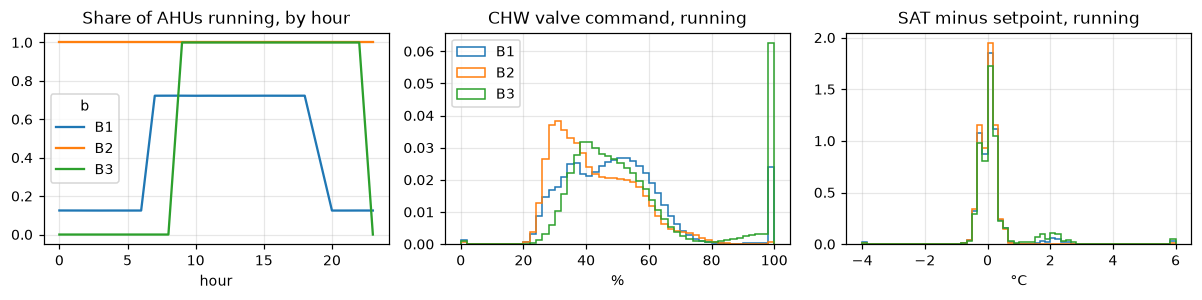

In [7]:
df = add_physics(df, meta)
run = df[df.steady]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
sched = df.assign(b=df.ahu_id.str[:2], h=df.timestamp.dt.hour).groupby(["b", "h"]).fan_status.mean().unstack(0)
sched.plot(ax=ax[0]); ax[0].set_title("Share of AHUs running, by hour"); ax[0].set_xlabel("hour")
for b, g in run.groupby(run.ahu_id.str[:2]):
    ax[1].hist(g.chw_valve_cmd_pct, bins=50, histtype="step", density=True, label=b)
    ax[2].hist(g.sat_err.clip(-4, 6), bins=60, histtype="step", density=True, label=b)
ax[1].set_title("CHW valve command, running"); ax[1].set_xlabel("%"); ax[1].legend()
ax[2].set_title("SAT minus setpoint, running"); ax[2].set_xlabel("°C")
fig.tight_layout(); fig.savefig(FIG / "patterns.png", dpi=170)

The left chart shows the three schedules. B2 (hospital) runs all 24 hours, B3 (mall) runs from about 09h00 to 23h00 every day, and B1 (office) runs about 72% of units in the daytime because the curve averages in weekends, with a 12% floor at night from the two units that run around the clock. The middle chart shows the valve mostly between 25% and 70%, with a spike at 100% in B3 and B1. The right chart shows SAT mostly within 0.3 °C of setpoint, with a second small hump near +2 °C in the same two buildings. The next cell traces both humps to three units.

In [8]:
lab_rows = pd.Series(False, index=run.index)
for e in labels.itertuples():
    lab_rows |= (run.ahu_id == e.ahu_id) & run.timestamp.between(e.start, e.end)
unit = run[~lab_rows & (run.split == "train")].groupby("ahu_id").agg(
    valve_at_100=("chw_valve_cmd_pct", lambda s: (s > 95).mean()), sat_err=("sat_err", "median"),
    fan=("fan_speed_pct", "median"), static_err=("static_err", "median"), filter_max=("filter_dp_pa", "max"))
unit.round(2).sort_values("valve_at_100", ascending=False).head(8)

,valve_at_100,sat_err,fan,static_err,filter_max
ahu_id,,,,,
B1-AHU-05,0.84,1.9,99.500000,-34.0,262.0
B3-AHU-09,0.78,1.9,98.800003,-18.0,269.0
B3-AHU-02,0.73,1.5,98.699997,-15.0,266.0
B1-AHU-01,0.00,0.0,72.400002,0.0,178.0
B3-AHU-03,0.00,0.0,69.199997,0.0,231.0
B2-AHU-08,0.00,0.0,54.599998,0.0,169.0
B2-AHU-09,0.00,0.0,47.599998,0.0,123.0
B2-AHU-10,0.00,0.0,62.000000,0.0,252.0


Three units run flat out all the time, *outside* any labelled event (B1-AHU-05, B3-AHU-02 and B3-AHU-09). Their valve is above 95% for 73% to 84% of running time, the fan runs near 99%, and SAT still sits 1.5 to 1.9 °C above setpoint. The next unit in the table never opens its valve past 95%. That is an undersized or chronically degraded unit (fouled coil, high filter loss, low CHW flow), not a model artefact. These go on the client checklist. They also matter for modelling, because a "low coil capacity" fault on a unit whose valve is already at 100% cannot show up as more valve opening.

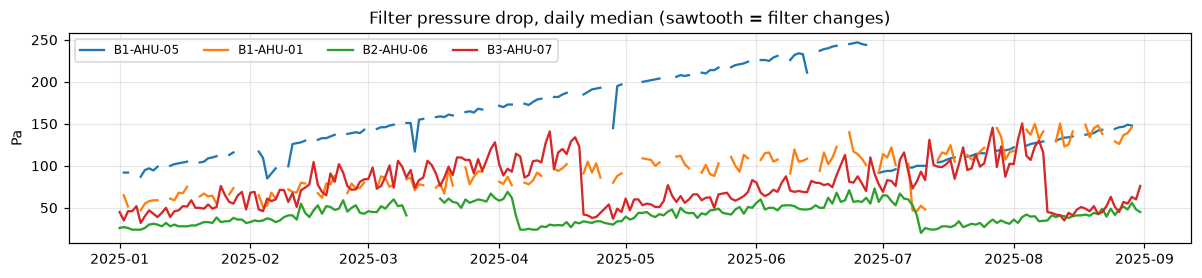

In [9]:
fig, ax = plt.subplots(figsize=(11, 2.6))
for a in ["B1-AHU-05", "B1-AHU-01", "B2-AHU-06", "B3-AHU-07"]:
    s = df[(df.ahu_id == a) & df.steady].set_index("timestamp").filter_dp_pa.resample("1D").median()
    ax.plot(s, label=a)
ax.set_title("Filter pressure drop, daily median (sawtooth = filter changes)"); ax.set_ylabel("Pa"); ax.legend(ncol=4, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "filter_dp.png", dpi=170)

Filter pressure drop follows a sawtooth. B3-AHU-07 drops from about 140 to 45 Pa in mid April and again from 150 to 45 Pa in early August, and B2-AHU-06 drops in April and July, which are filter changes. B1-AHU-05 climbs from 90 to about 250 Pa over six months before its change in late June, which helps explain why it runs saturated. Filter loading is normal ageing, not a labelled fault, so the normal-behaviour models take filter pressure drop into account instead of flagging it.

## 4. Fault signatures, physics vs labels

For each labelled event the table takes the median of each signal during the event minus the same AHU's median over the 7 days before it (steady running rows only), then the median of that change per fault type.

In [10]:
SIG = {"sat_err": "SAT − SP (°C)", "chw_valve_cmd_pct": "valve (%)", "coil_dt": "coil ΔT (°C)",
       "oaf": "OA fraction", "mix_dt": "MAT − RAT (°C)", "oa_damper_cmd_pct": "damper cmd (%)",
       "co2_ppm": "CO2 (ppm)", "fan_speed_pct": "fan (%)", "static_err": "static err (Pa)"}
rows = []
for e in labels.itertuples():
    g = run[run.ahu_id == e.ahu_id]
    during = g[g.timestamp.between(e.start, e.end)][list(SIG)].median()
    before = g[g.timestamp.between(e.start - pd.Timedelta("7D"), e.start - pd.Timedelta("1D"))][list(SIG)].median()
    rows.append((during - before).rename(f"{e.ahu_id} {e.fault_type}").to_frame().T.assign(fault=e.fault_type))
delta = pd.concat(rows)
sig = delta.groupby("fault")[list(SIG)].median().rename(columns=SIG)
sig.round(2)

,SAT − SP (°C),valve (%),coil ΔT (°C),OA fraction,MAT − RAT (°C),damper cmd (%),CO2 (ppm),fan (%),static err (Pa)
fault,,,,,,,,,
chw_valve_stuck,5.8,19.60,-4.10,0.00,-0.15,0.0,-24.75,15.40,-76.5
low_coil_capacity,0.1,11.45,-0.20,0.00,0.00,0.0,-4.00,0.10,-1.0
oa_damper_stuck,0.0,-0.65,-0.50,-0.11,-0.60,40.0,586.00,0.20,0.0
sat_sensor_bias,0.0,0.65,0.05,0.00,0.00,0.0,40.00,3.05,0.0


Each fault moves a different set of signals. Stuck valves move the most (SAT +5.8 °C, valve +19.6%, coil ΔT −4.1 °C, fan +15.4%). Stuck dampers have their own signature (OA fraction −0.11, damper command +40%, CO2 +586 ppm). Low coil capacity mostly moves the valve (+11.5%) with SAT almost on setpoint (+0.1 °C). Sensor bias barely moves any median (fan +3.1%, CO2 +40 ppm), which makes it the hardest fault to see.

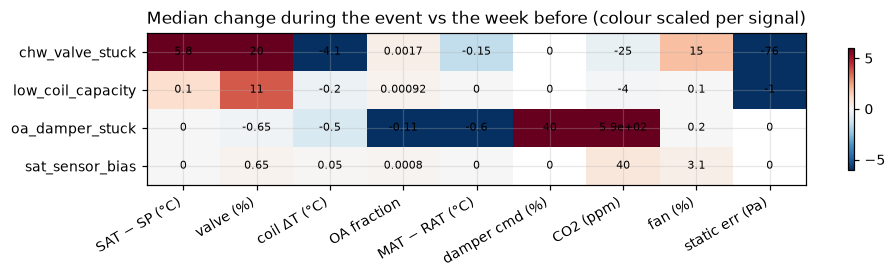

In [11]:
z = sig / delta[list(SIG)].abs().median().values
fig, ax = plt.subplots(figsize=(9, 2.6))
im = ax.imshow(z.clip(-6, 6), cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
ax.set_xticks(range(len(SIG))); ax.set_xticklabels(SIG.values(), rotation=30, ha="right")
ax.set_yticks(range(len(z))); ax.set_yticklabels(z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = sig.iloc[i, j]
        if pd.notna(v): ax.text(j, i, f"{v:.2g}", ha="center", va="center", fontsize=7)
ax.set_title("Median change during the event vs the week before (colour scaled per signal)")
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); fig.savefig(FIG / "fault_signatures.png", dpi=170)

The heat map shows the same table with each signal scaled to its own typical change, so small but consistent moves such as the 0.11 drop in OA fraction stand out as clearly as the 586 ppm rise in CO2. Every fault except sensor bias has at least one signal coloured at the edge of the scale.

In [12]:
delta.round(2).sort_values("fault")

,sat_err,chw_valve_cmd_pct,coil_dt,oaf,mix_dt,oa_damper_cmd_pct,co2_ppm,fan_speed_pct,static_err,fault
B1-AHU-06 chw_valve_stuck,12.10,39.20,-7.90,0.01,-0.30,0.0,-74.0,29.80,-97.0,chw_valve_stuck
B3-AHU-09 chw_valve_stuck,3.90,0.00,-2.40,-0.00,-0.10,0.0,NaN,1.00,-69.0,chw_valve_stuck
B1-AHU-04 chw_valve_stuck,-5.60,-51.30,5.60,0.01,0.00,0.0,96.0,-25.40,0.0,chw_valve_stuck
B3-AHU-06 chw_valve_stuck,10.70,45.00,-7.60,-0.00,-0.40,0.0,NaN,38.30,-111.0,chw_valve_stuck
B2-AHU-08 chw_valve_stuck,11.00,55.00,-8.40,-0.01,-0.20,-1.3,-113.0,46.55,-93.0,chw_valve_stuck
B3-AHU-03 chw_valve_stuck,7.70,47.20,-5.80,0.01,-0.20,0.0,NaN,31.30,-84.0,chw_valve_stuck
B3-AHU-10 chw_valve_stuck,-4.50,-38.60,4.00,-0.00,0.10,0.0,NaN,-8.65,0.0,chw_valve_stuck
B2-AHU-10 chw_valve_stuck,-4.90,-54.30,3.40,0.01,0.10,0.0,24.5,-18.60,0.0,chw_valve_stuck
B1-AHU-07 low_coil_capacity,0.10,31.65,-0.10,-0.00,0.10,0.0,-25.0,0.15,-1.0,low_coil_capacity
B2-AHU-04 low_coil_capacity,0.10,8.45,-0.00,0.00,0.10,-0.4,-7.0,-1.65,0.0,low_coil_capacity


Per event, stuck valves go both ways. Three events (B1-AHU-04, B2-AHU-10, B3-AHU-10) show SAT 4.5 to 5.6 °C *below* setpoint with the valve closing by 39% to 54% (stuck open), while the other five show SAT 3.9 to 12.1 °C above setpoint (stuck closed). The classifier therefore needs the sign as well as the size of the change. On the saturated units B1-AHU-05, B3-AHU-02 and B3-AHU-09 the valve change is 0 because it already sits at 100%, and the fault only shows as SAT rising. Sensor bias moves the fan by 8% to 20% per event, but in both directions, which is why its median is small.

## 5. Looks like a fault, but no label (test period)

In [13]:
cols = ["fan_speed_pct", "chw_valve_cmd_pct", "sat_err", "oaf"]
st = df[df.steady].assign(m=df.timestamp.dt.month)
base = st[st.m.isin([4, 5, 6])].groupby("ahu_id")[cols].median()
chg = pd.concat({m: st[st.m == m].groupby("ahu_id")[cols].median() - base for m in (7, 8)}, axis=1)
score = (chg / st.groupby("ahu_id")[cols].std().pipe(lambda s: pd.concat({7: s, 8: s}, axis=1))).abs().max(axis=1)
chg.round(2).loc[score.sort_values(ascending=False).index[:8]]

7                                             8                               
          fan_speed_pct chw_valve_cmd_pct sat_err   oaf fan_speed_pct chw_valve_cmd_pct sat_err  oaf
ahu_id                                                                                              
B2-AHU-12          -0.9              -1.5     0.0 -0.04           1.6               1.3     0.0  0.0
B1-AHU-12          -6.6              -1.3     0.0  0.00          -2.3               0.6     0.0  0.0
B3-AHU-06          -6.3              -1.7     0.0  0.00          -6.3              -0.9     0.0  0.0
B1-AHU-16           3.6               2.3     0.1  0.00          -0.2              -0.1     0.0  0.0
B1-AHU-01          -4.0              -2.8    -0.1  0.01           2.5               2.2     0.0  0.0
B3-AHU-08          -2.2              -1.1     0.0  0.00           0.0               1.1     0.0 -0.0
B3-AHU-04          -0.2              -0.3     0.0 -0.00           2.3               1.9     0.0  0.0
B3-AHU-05           2.7               1.7     0.1  0.00           2.1               1.0     0.0  0.0

Against April to June, three units stand out in the test period. B1-AHU-12 and B3-AHU-06 run their fans 6.6% and 6.3% slower in July with the valve roughly unchanged, and B2-AHU-12 takes in less outdoor air in July (OA fraction −0.04). None of these moves is large, but they persist for weeks, and notebook 02's model raises sustained alarms on all three. They are worth a site check.